<a href="https://colab.research.google.com/github/Kittu6705/python-sales-data-analysis/blob/main/sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SALES ANALYSIS REPORT
---------------------
Total Revenue: Rs. 187,500.00
Total Units Sold: 23

Sales by Product:
 Product  Units_Sold  Total_Revenue
  Laptop         3.0       135000.0
 Monitor         3.0        36000.0
Keyboard         8.0        12000.0
   Mouse         9.0         4500.0

Highest-revenue product: Laptop


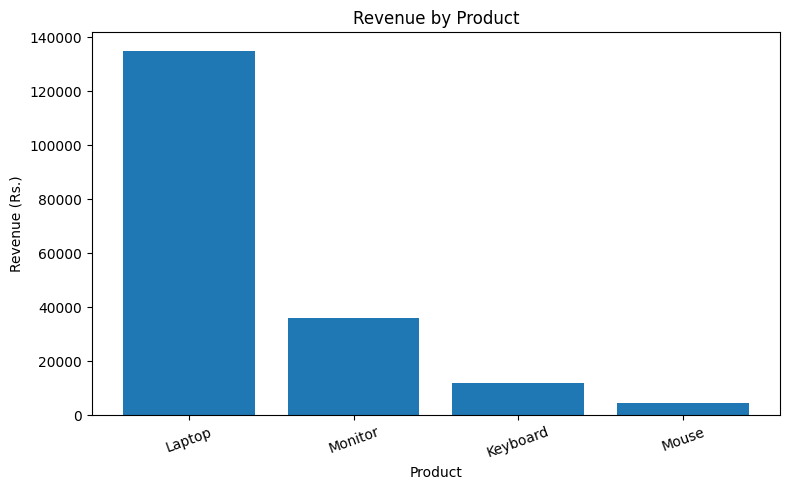


Files created:
cleaned_sales.csv
sales_summary.csv
sales_chart.png
sales_report.txt


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Create a sample sales dataset
data = {
    "Date": [
        "2026-10-01", "2026-10-01", "2026-10-02",
        "2026-10-02", "2026-10-03", "2026-10-03",
        "2026-10-04", "2026-10-04", "2026-10-05"
    ],
    "Product": [
        "Laptop", "Mouse", "Keyboard", "Laptop",
        "Mouse", "Monitor", "Keyboard", "Monitor", "Laptop"
    ],
    "Quantity": [2, 5, 3, 1, 4, 2, 5, 1, 2],
    "Price": [45000, 500, 1500, 45000, 500, 12000, 1500, 12000, 45000]
}

df = pd.DataFrame(data)

# 2. Add a few data-quality issues for practice
df.loc[8, "Quantity"] = None
df = pd.concat([df, df.iloc[[0]]], ignore_index=True)

# 3. Clean the data
df = df.drop_duplicates()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

df = df.dropna(subset=["Date", "Product", "Price"])
df["Quantity"] = df["Quantity"].fillna(0)

# 4. Calculate revenue
df["Revenue"] = df["Quantity"] * df["Price"]

# 5. Summarize sales by product
summary = (
    df.groupby("Product", as_index=False)
    .agg(
        Units_Sold=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
)

total_revenue = df["Revenue"].sum()
total_units = df["Quantity"].sum()

print("SALES ANALYSIS REPORT")
print("---------------------")
print(f"Total Revenue: Rs. {total_revenue:,.2f}")
print(f"Total Units Sold: {total_units:,.0f}")
print("\nSales by Product:")
print(summary.to_string(index=False))

best_product = summary.iloc[0]["Product"]
print(f"\nHighest-revenue product: {best_product}")

# 6. Create a chart
plt.figure(figsize=(8, 5))
plt.bar(summary["Product"], summary["Total_Revenue"])
plt.title("Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue (Rs.)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("sales_chart.png", dpi=150)
plt.show()

# 7. Export project results
df.to_csv("cleaned_sales.csv", index=False)
summary.to_csv("sales_summary.csv", index=False)

with open("sales_report.txt", "w", encoding="utf-8") as file:
    file.write("SALES ANALYSIS REPORT\n")
    file.write(f"Total Revenue: Rs. {total_revenue:,.2f}\n")
    file.write(f"Total Units Sold: {total_units:,.0f}\n")
    file.write(f"Highest-revenue product: {best_product}\n\n")
    file.write(summary.to_string(index=False))

print("\nFiles created:")
print("cleaned_sales.csv")
print("sales_summary.csv")
print("sales_chart.png")
print("sales_report.txt")
